## Results Pipeline Decision Task Clean Theta
A notebook that produces all results for the clean theta condition and the corresponding plots and implements seeding.

In [62]:
# Imports
import sys # for path management
import os

# Add HandcraftApproach directory to path
ha_path = os.path.abspath("/Users/liviastein/STDP_Theta-1/STDP-SR_scripts/Task_Setup/HandcraftApproach")
if ha_path not in sys.path:
    sys.path.insert(0, ha_path)

import importlib
import MazeAgent_HA as MA
importlib.reload(MA)

import copy
import tomplotlib.tomplotlib as tpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
import imageio
import random
import pandas as pd
from tqdm.notebook import tqdm
from seqnmf import seqnmf, plot

%load_ext autoreload
%autoreload 1

#for plotting in notebook
%matplotlib inline

# define a list of random seeds to loop through for runs of the same experiment
#random_seeds = [0, 42]
random_seeds = [0, 2, 4, 6, 42]
#random_seeds = [0]


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Define Agent and Parameters

**General Parameters**
- N = 40 basis features per arm
- peak firing rate = 10Hz
- Theta Frequency = 10Hz
- phase locking parameter kappa = 10

**Scrambling Parameters**
- scramble strength = 1.0
- HF jitter = 1.0

**Goal Details**
- goal coordinates = [5.25, 8.0]
- goal raduis = 0.5
- reward = 1.0

Setting parameters
Initialising
   making state/history dataframes
   initialising velocity, position and direction
   setting time/run counters
   initialising theta phases: clean and scrambled
   making the maze walls
   setting goal location and reward
   discretising position for later plotting
   handling undefined parameters
   initialising basis features for learning
   calculating state vector at all discretised positions


  0%|          | 0/550000 [00:00<?, ?it/s]

   initialising STDP weight matrix and traces
   Adding 'theta scrambled' Condition
   calculating value function based on distance to goal
DONE


(<Figure size 900x1200 with 1 Axes>, <Axes: >)

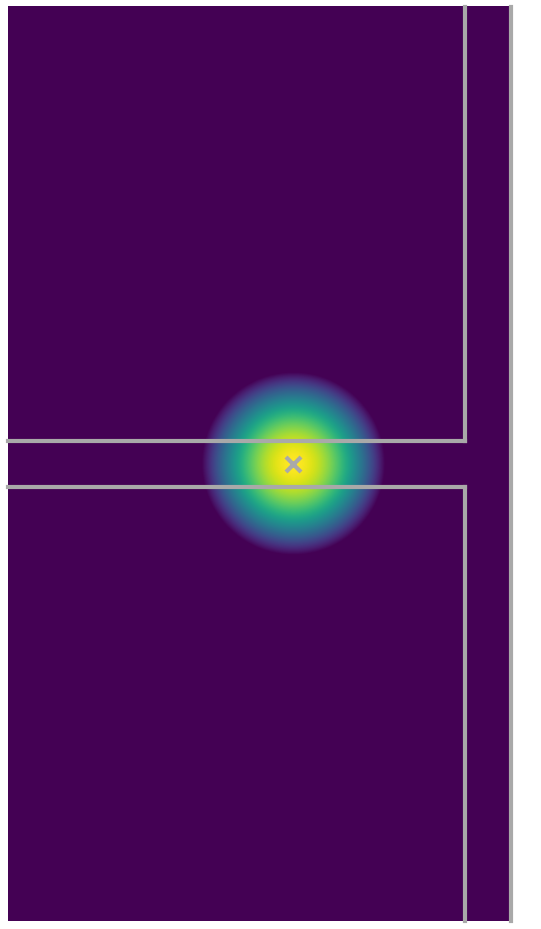

In [32]:
# set up place cells
N = 40
mazeSize = 5.0

# Scale the original TMaze layout to the larger maze
xcen = np.concatenate((
    np.linspace(0.02, 1.00, N) * mazeSize, 
    1.05 * mazeSize * np.ones(N), # 1.05 * mazeSize is the x-coordinate of the rightmost wall of the maze
    1.05 * mazeSize * np.ones(N) # 
))
ycen = np.concatenate((
    np.ones(N) * mazeSize,
    np.linspace(1.03, 2.00, N) * mazeSize, 
    np.linspace(0.97, 0.00, N) * mazeSize
))
centres = np.vstack((xcen, ycen)).T


# set parameters for the MazeAgent class
params = {
           #Maze params 
          'mazeType'            : 'TMaze',  #type of maze, define in getMaze() function
          'stateType'           : 'gaussianThreshold', #feature on which to TD learn (onehot, gaussian, gaussianCS, circles, bump)
          'movementPolicy'      : 'windowsScreensaver',  #movement policy (raudies, random walk, windows screensaver)
          'roomSize'            : mazeSize,          #maze size scaling parameter, metres
          'dt'                  : 0.01,       #simulation time disretisation (defualts to largest )
          'dx'                  : 0.01,       #space discretisation (for plotting, movement is continuous)
          'speedScale'          : 0.16,       #movement speed scale, metres/second
          'rotSpeedScale'       : None,       #rotational speed scale, radians/second
          'initPos'             : None,  #initial position [x0, y0], metres
          'initDir'             : None,      #initial direction, unit vector
          'nCells'              : N,       #how many features to use
          'centres'             : centres,       #array of receptive field positions. Overwrites nCells
          'sigma'               : 1,          #basis cell width scale (irrelevant for onehots)
          'doorsClosed'         : True,       #whether doors are opened or closed in multicompartment maze
          'reorderCells'        : False,       #whether to reorde the cell centres which have been provided
          'firingRateLookUp'    : False,      #use quantised lookup table for firing rates 
          'biasDoorCross'       : False,      #if True, in twoRoom maze door crossings are biased towards
          'biasWallFollow'      : True,       #if True, agent aligns to wall when gets too near.

          #TD params 
          'tau'                 : 4,          #TD decay time, seconds
          'TDdx'                : 0.1,       #rough distance between TD learning updates, metres 
          'alpha'               : 0.01,       #TD learning rate 
          'successorFeatureNorm': 100,        #linear scaling on successor feature definition found to improve learning stability
          'TDreg'               : 0.01,       #L2 regularisation 
          
          #STDP params
          'peakFiringRate'      : 10,          #peak firing rate of a cell (middle of place field,preferred theta phase)
          'tau_STDP_plus'       : 20e-3,      # was 20 pre trace decay time
          'tau_STDP_minus'      : 40e-3,      #was 40 post trace decay time
          'a_STDP'              : -0.4,       # was -0.4, pre-before-post potentiation factor (post-before-pre = 1) 
          'eta'                 : 0.01,       #STDP learning rate
          'baselineFiringRate'  : 0,          #baseline firing rate for cells 
          'use_full_STDP_rule'  : True,      #whether to use full STDP rule     
          'online_mapping'      : 'identity',  #how to map CA3-->CA1 during learning
          'rownorm'             : False,

          #Theta precession params
          'thetaFreq'           : 10,         #theta frequency
          'precessFraction'     : 0.5,        #fraction of 2pi the prefered phase moves through
          'kappa'               : 5,          # von mises spread parameter
          
          #Theta scrambling params (Livi addition)
          'scramble_strength'    : 1.0,        # strength of theta phase scrambling 
          'hf_strength'          : 1.0,        # strength of high frequency jitter added to scrambled theta phase

          # Goal Location
          'goalPos'             : [5.25, 8.0], # 7.5 before. position of goal in metres -> given as array of shape [x, y]
          'goalRadius'          : 0.5,       # radius of goal in metres
          'goalReward'          : 1.0,

}

agent_CT = MA.MazeAgent(params)
plotter = MA.Visualiser(agent_CT)
agent_CT.toggleDoors(doorsClosed=False)

#plotter.plotMazeStructure() # plot maze structure to check it's correct before starting simulation
plotter.plotReceptiveField(24) # plot receptive field of place cell 5 in the middel of loop
#plotter.plotFeatureCells(centresOnly=True, textlabel=False) # plots centres of the place cells in maze (no heatmap)
#fig, ax = plotter.plotFeatureCells(shufflebeforeplot=False, textlabel=True)
#plotter.plotGoal()

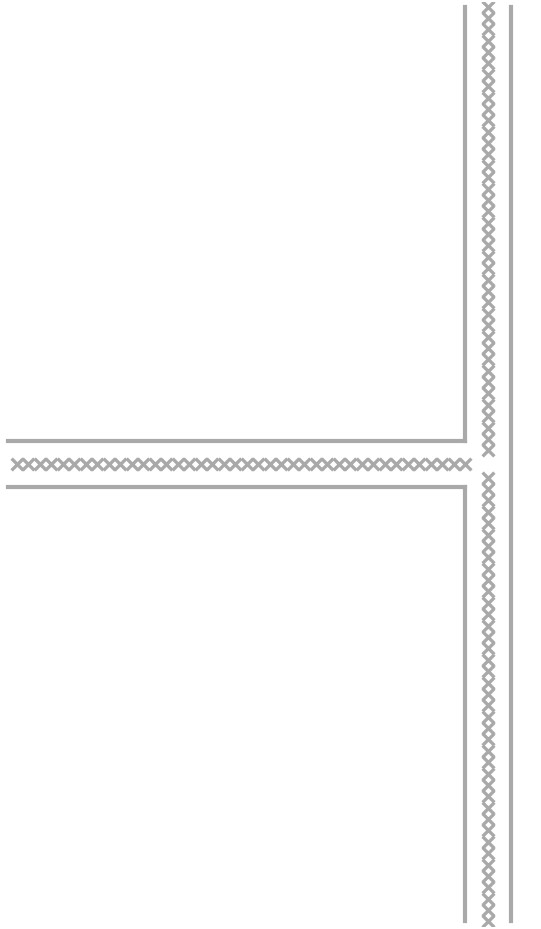

In [33]:
plotter=MA.Visualiser(agent_CT)
plotter.plotFeatureCells( centresOnly=True, textlabel=False)
# save figure with transparent background
plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/MazeFeatureCells.png", transparent=True)

### Make some plots of the Maze, Value Function, Cells
- Value function
- feature cells + maze structure

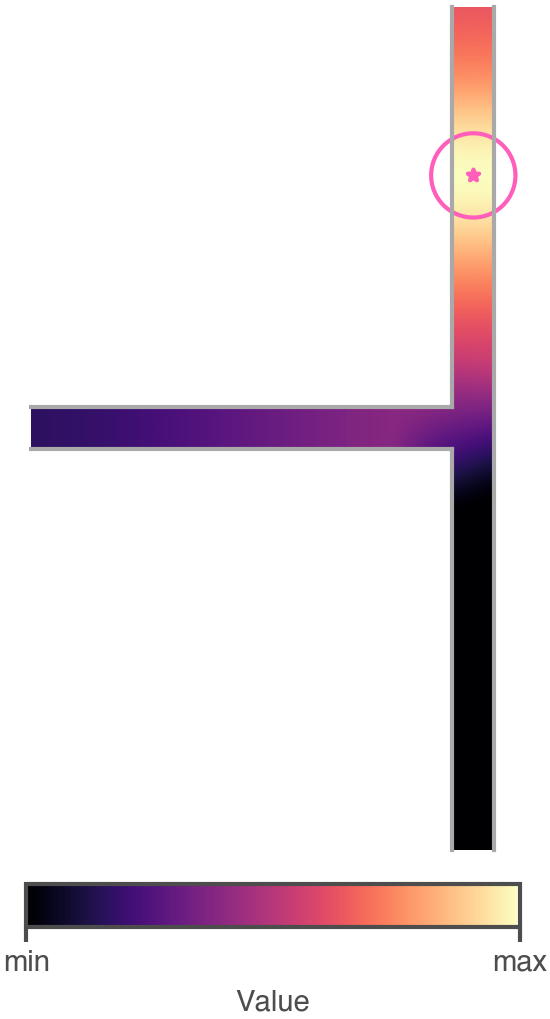

In [34]:
# plot value function
plotter = MA.Visualiser(agent_CT)

plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')

# plot value function
fig = plotter.valueFunctionHeatMap(fig=None, ax=None, smoothing=1, showGoal=True, showCentres=False, save=False)
plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/ValueFunction2.pdf", transparent=True)

# plot feature cells
#plotter.plotFeatureCells(shufflebeforeplot=False, textlabel=True)


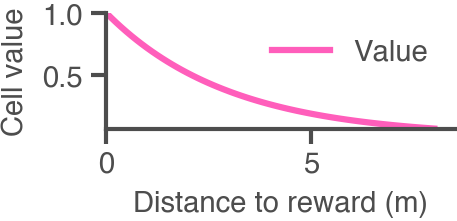

In [35]:
# New plot of value function values with value function values on y axis and cell distance to reward on x axis
# Value of each cell as a function of its distance to the reward
# Uses the same implementation as MazeAgent_HA.getCellValues
plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')
Livi_palette = {
    "türkis": '#66dfd8',
    "lBlue": '#1097d3',
    "dViolet": '#5e17eb',
    "lpurple": '#8c52ff',
    "altRosa": '#cb6ce6',
    "lRosa": '#e2a9f1',
    "pink": '#ff5ebb'
}

sigma = 3.0
manualCutoff = True

# Use the already-defined agent in your notebook
cell_centres = agent_CT.centres
goal_pos = np.asarray(agent_CT.goalPos, dtype=float).reshape(2,)

# Distance from each cell centre to the goal
distances = np.linalg.norm(cell_centres - goal_pos, axis=1)

# Values from the actual implementation in MazeAgent_HA
cell_values = agent_CT.getCellValues(sigma=sigma, manualCutoff=manualCutoff)

# Sort by distance for a cleaner line plot
order = np.argsort(distances)
distances_sorted = distances[order]
cell_values_sorted = cell_values[order]

# The underlying formula used by getCellValues, before the optional manual cutoff
value_curve = np.exp(-distances_sorted / sigma)
value_curve = value_curve / np.max(value_curve)

fig, ax = plt.subplots(figsize=(1.5,0.5))

# One point per cell
#ax.scatter(distances, cell_values, s=45, alpha=0.75, color="#ff66c4", edgecolor="#531CB3")

# Smoothed view of the same relationship
#ax.plot(distances_sorted, cell_values_sorted, color="#531CB3", linewidth=1.5, alpha=0.7)

# Reference curve from the actual formula
ax.plot(distances_sorted, value_curve, color=Livi_palette["pink"], linestyle="-", label="Value", linewidth=1.5)

ax.set_xlabel("Distance to reward (m)")
ax.set_ylabel("Cell value")
ax.set_xlim(0, np.max(distances_sorted)+0.5)
#ax.set_title("Cell value as a function of distance to reward")
ax.legend()
#plt.tight_layout()
#plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/CellValueVsDistance.pdf", transparent=True)
plt.show()



### Pretrain the Agent
- pretrain for 30 minutes  under different conditions
    - TD learning
    - STDP Learning
        - clean theta (10Hz)
        - no theta
        - scrambled theta (1.0; 1.0)
- plot weight matrices for all conditions

**Pretrain Policy**
- Choose left (correct arm) in 90% of cases and right (incorrect) arm in remaining 10% of cases

  0%|          | 0/180000 [00:00<?, ?it/s]

Calculating place and grid cells


(<Figure size 300x300 with 2 Axes>,
 <Axes: title={'center': "SR matrix 'W' after 30min of STDP learning without theta modulation"}>,
 <Axes: >)

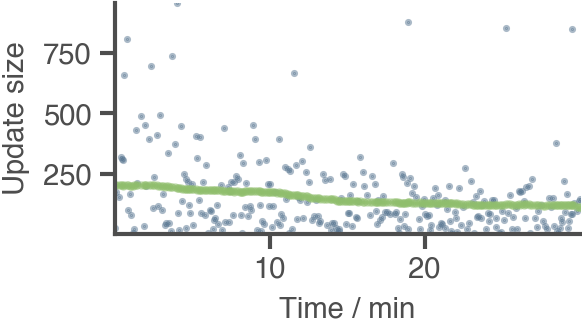

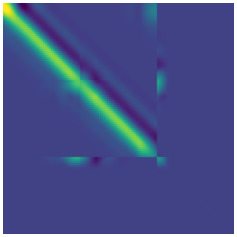

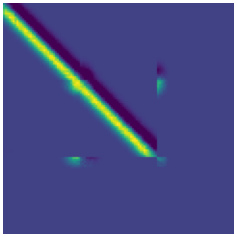

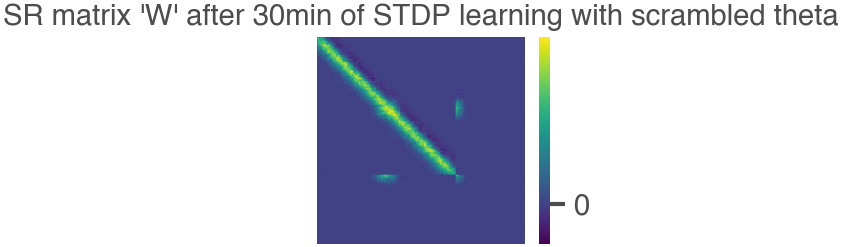

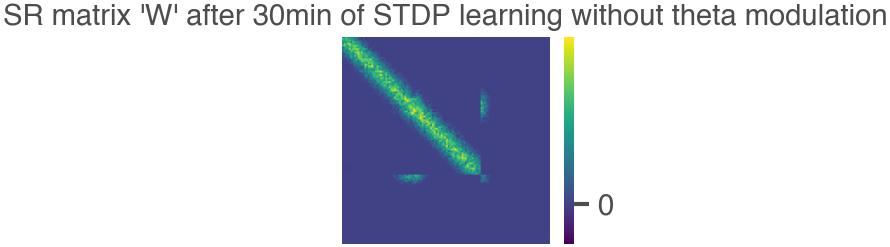

In [36]:
agent_CT.pos = np.array([0, mazeSize]) # start at the stem center in the scaled T maze
agent_CT.dir = np.array([1,0]) # start facing right at the start of the stem
agent_CT.runRat(trainTime=30, STDPLearn=True, TDSRLearn=True, saveEvery=0.5)

# Plot Trajectory for control
plotter = MA.Visualiser(agent_CT)
#fig, ax = plotter.plotMazeStructure()
#plottimestart, plottimeend = 0, 1
# plotter.plotTrajectory(fig=fig, ax=ax, starttime=plottimestart, endtime=plottimeend)

# Plot SRs fro control
plotter.plotM(whichM="M", colorbar=False, title=None, save= False) 
plotter.plotM(whichM="W", colorbar=False, title=None, save=False)
# Plot scrambled
plotter.plotM(whichM="W_scrambled", colorbar=True, title="SR matrix 'W' after 30min of STDP learning with scrambled theta", save=False) 
# Plot no_theta
plotter.plotM(whichM="W_notheta", colorbar=True, title="SR matrix 'W' after 30min of STDP learning without theta modulation", save=False)


### Decision Task with Pretrained Agent - CLEAN THETA

Running seed 0...
Timeout: 90.0s
dt: 0.01s
Steps: 9000
Expected final elapsed: 90.0s
Epsilon threshold: 89.999999999


  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/9500 [00:00<?, ?it/s]

/Users/liviastein/STDP_Theta-1/STDP-SR_scripts/Task_Setup/HandcraftApproach/MazeAgent_HA.py:1030: RuntimeWarning: overflow encountered in exp
  preTrace        *= np.exp(- timeDiff / self.tau_STDP_plus) #traces for all cells decay...
/Users/liviastein/STDP_Theta-1/STDP-SR_scripts/Task_Setup/HandcraftApproach/MazeAgent_HA.py:1030: RuntimeWarning: invalid value encountered in multiply
  preTrace        *= np.exp(- timeDiff / self.tau_STDP_plus) #traces for all cells decay...
/Users/liviastein/STDP_Theta-1/STDP-SR_scripts/Task_Setup/HandcraftApproach/MazeAgent_HA.py:1031: RuntimeWarning: overflow encountered in exp
  postTrace       *= np.exp(- timeDiff / self.tau_STDP_minus) #traces for all cells decay...
/Users/liviastein/STDP_Theta-1/STDP-SR_scripts/Task_Setup/HandcraftApproach/MazeAgent_HA.py:1031: RuntimeWarning: invalid value encountered in multiply
  postTrace       *= np.exp(- timeDiff / self.tau_STDP_minus) #traces for all cells decay...
/Users/liviastein/STDP_Theta-1/STDP-SR_scr

Goal reached! Duration: 47.469999999999125. Starting new episode!
Calculating place and grid cells


  0%|          | 0/9500 [00:00<?, ?it/s]

... (98 outputs left out)

  0%|          | 0/9500 [00:00<?, ?it/s]

Goal reached! Duration: 45.82999999995832. Starting new episode!
Calculating place and grid cells


  0%|          | 0/9500 [00:00<?, ?it/s]

Goal reached! Duration: 49.49999999995498. Starting new episode!
Calculating place and grid cells
SUMMARY FOR SEED 0 ONLY!:
Seed 0 Summary:
  Total Episodes: 10
  Reached Goal: 8
  Timeouts: 2
  Wrong Arm Choices: 0
  Percentage Correct: 80.00%
  Average Time to Goal: 50.34374999996623
SUMMARY FOR SEED 2 ONLY!:
Seed 2 Summary:
  Total Episodes: 10
  Reached Goal: 7
  Timeouts: 2
  Wrong Arm Choices: 1
  Percentage Correct: 70.00%
  Average Time to Goal: 49.298571428532505
SUMMARY FOR SEED 4 ONLY!:
Seed 4 Summary:
  Total Episodes: 10
  Reached Goal: 10
  Timeouts: 0
  Wrong Arm Choices: 0
  Percentage Correct: 100.00%
  Average Time to Goal: 53.062999999966245
SUMMARY FOR SEED 6 ONLY!:
Seed 6 Summary:
  Total Episodes: 10
  Reached Goal: 8
  Timeouts: 2
  Wrong Arm Choices: 0
  Percentage Correct: 80.00%
  Average Time to Goal: 50.444999999959315
SUMMARY FOR SEED 42 ONLY!:
Seed 42 Summary:
  Total Episodes: 10
  Reached Goal: 8
  Timeouts: 2
  Wrong Arm Choices: 0
  Percentage Correct:

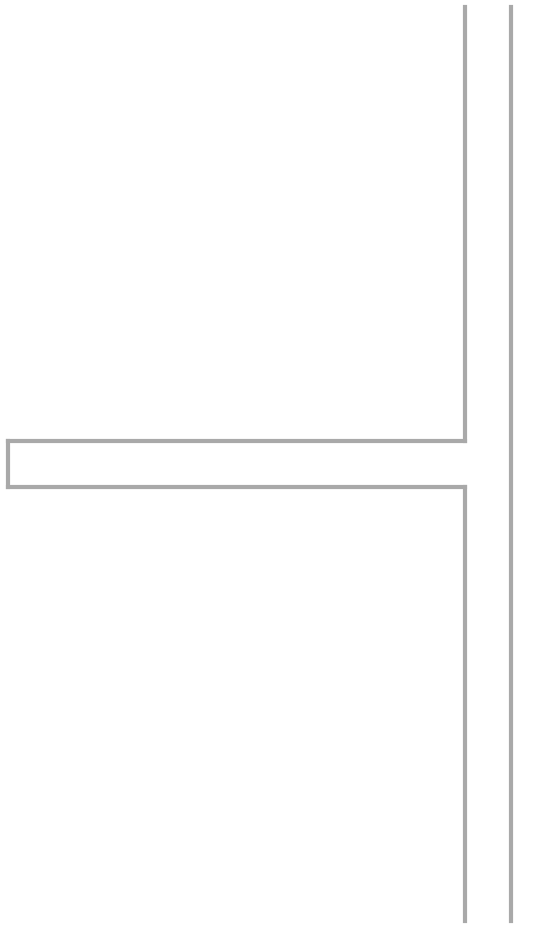

In [37]:
# adapt maze and close off open stem
if agent_CT.mazeType == "TMaze":
    rs = agent_CT.roomSize
    corridor_half_width = 0.05 * rs
    agent_CT.walls['CloseStem'] = np.array([[[0.0, rs-corridor_half_width], [0.0, rs+corridor_half_width]]])
    agent_CT.mazeState['walls'] = agent_CT.walls.copy()
    agent_CT.toggleDoors(doorsClosed=False)
    agent_CT.discreteStates = agent_CT.positionArray_to_stateArray(agent_CT.discreteCoords, stateType= agent_CT.stateType)
    snapshot = pd.DataFrame({'t': [agent_CT.t], 'M': [agent_CT.M.copy()], 'W': [agent_CT.W.copy()], 'W_notheta':[agent_CT.W_notheta.copy()], 'W_scrambled':[agent_CT.W_scrambled.copy()], 'mazeState':[agent_CT.mazeState]})
    agent_CT.snapshots = pd.concat([agent_CT.snapshots, snapshot], ignore_index=True)

# check if maze is changed correctly
plotter = MA.Visualiser(agent_CT)
plotter.plotMazeStructure()

# run a number of task episodes with pretrained agent (agent_CT) for each random seed in the list defined earlier, and save results for each seed in a dictionary
results = {}
for seed in random_seeds:
    print(f"Running seed {seed}...")
    np.random.seed(seed); random.seed(seed)

    # save results for seed
    results[seed] = {'episode_logs': [], "episodes": [], "params": params} # to store outcome of each episode for this seed, which we will later use to summarise performance across seeds

    # snapshot agent baseline state 
    base_history_len = len(agent_CT.history)
    base_snap_len = len(agent_CT.snapshots)
    baseline_t = agent_CT.t

    #baseline_theta = getattr(agent_CT, "thetaPhase", 0.0)
    #baseline_theta_scrambled = getattr(agent_CT, "thetaPhase_scrambled", 0.0)
    #baseline_spikedata = copy.deepcopy(getattr(agent_CT, "spikedata", {}))
    #baseline_spikedata_by_condition = copy.deepcopy(getattr(agent_CT, "spikedata_by_condition", {}))
    #baseline_decoded = copy.deepcopy(getattr(agent_CT, "decoded_dir_history", []))
    baseline_runID = agent_CT.runID

    M_before = agent_CT.M.copy()
    W_before = agent_CT.W.copy()
    W_notheta_before = agent_CT.W_notheta.copy()
    W_scrambled_before = agent_CT.W_scrambled.copy()

    # reset episode-local state (clean start, keep weights)
    agent_CT.pos = np.array([0.2, mazeSize])            # or [0, mazeSize] per your convention
    agent_CT.dir = np.array([1.0, 0.0])
    agent_CT.speed = agent_CT.speedScale
    agent_CT.t = 0.0
    agent_CT.thetaPhase = 0.0
    agent_CT.thetaPhase_scrambled = 0.0
    agent_CT.thetaPhase_scrambled_history = []
    agent_CT.thetaPhase_scrambled_time_history = []

    agent_CT.spikedata = {'CA3': {'times': [], 'ids': []}, 'CA1': {'times': [], 'ids': []}}
    agent_CT.spikedata_by_condition = {
        'theta': {'CA1': {'times': [], 'ids': []}, 'CA3': {'times': [], 'ids': []}},
        'notheta': {'CA1': {'times': [], 'ids': []}, 'CA3': {'times': [], 'ids': []}},
        'scrambled': {'CA1': {'times': [], 'ids': []}, 'CA3': {'times': [], 'ids': []}}
    }
    agent_CT.decoded_dir_history = []
    agent_CT.reachedGoal = False
    agent_CT.goalReachedTime = 0.0
    agent_CT.lastTurnUpdate = -1
    agent_CT.randomTurnSpeed = 0
    agent_CT.doorPassage = False
    agent_CT.doorPassageTime = 0.0

    # Diagnostic: check timeout condition behavior
    timeout_test = 90.0
    dt_test = agent_CT.dt
    steps_test = int(timeout_test / dt_test)
    print(f"Timeout: {timeout_test}s")
    print(f"dt: {dt_test}s")
    print(f"Steps: {steps_test}")
    print(f"Expected final elapsed: {steps_test * dt_test}s")
    print(f"Epsilon threshold: {timeout_test - 1e-9}")


    # run decision task episodes
    episodes = 10
    for ep in tqdm(range(episodes)):
        history_start = len(agent_CT.history)
        snapshot_start = len(agent_CT.snapshots)
        t_start = agent_CT.t
        runid_start = agent_CT.runID
        decoded_dir_start = len(agent_CT.decoded_dir_history)


        outcome = agent_CT.TaskEpisode(saveEvery=0.5, 
                                        TDSRLearn=False, 
                                        STDPLearn=True, 
                                        condition = 'theta', 
                                        phase_threshold = 1.5*np.pi, 
                                        t_window =None,
                                        updateSTDPWeights = False,
                                        maxTurnAngle = True,
                                        maxAngle = 50.0,
                                        timeout = 95.0) # 95-5 as margin 
        # store outcome of episode
        history_end = len(agent_CT.history)
        snapshot_end = len(agent_CT.snapshots)
        t_end = agent_CT.t
        runid_end = agent_CT.runID
        decoded_dir_end = len(agent_CT.decoded_dir_history)

        assert runid_end == runid_start + 1, (
              f"runID mismatch at seed={seed}, ep={ep}: "
              f"start={runid_start}, end={runid_end}"
        )

        # metadata row for this episode
        metadata = {
            'seed': seed,
            'episode': ep,
            'runID_start': runid_start,
            'runID_end': runid_end,
            't_start': t_start,
            't_end': t_end,
            "duration": t_end - t_start,
            "history_start": history_start,
            "history_end": history_end,
            "snapshot_start": snapshot_start,
            "snapshot_end": snapshot_end,
            "outcome": outcome
        }
        results[seed]['episode_logs'].append(metadata)

        # payload data for this episode
        payload = {"history": agent_CT.history.iloc[history_start:history_end].reset_index(drop=True),
                   "decoded_dir_history": agent_CT.decoded_dir_history[decoded_dir_start:decoded_dir_end],
                     "snapshots": agent_CT.snapshots.iloc[snapshot_start:snapshot_end].reset_index(drop=True),
                     "spikedata": copy.deepcopy(agent_CT.spikedata),
                     "spikedata_by_condition": copy.deepcopy(agent_CT.spikedata_by_condition),
                     "final_weights": {
                          'M': agent_CT.M.copy(),
                          'W': agent_CT.W.copy(),
                          'W_notheta': agent_CT.W_notheta.copy(),
                          'W_scrambled': agent_CT.W_scrambled.copy()
                     }
          }       
        results[seed]['episodes'].append(payload)

    # save final outcome/weights if desired
    results[seed]["final_weights_pre_restore"] = {
        "M": agent_CT.M.copy(), "W": agent_CT.W.copy(),
        "W_notheta": agent_CT.W_notheta.copy(), "W_scrambled": agent_CT.W_scrambled.copy()
    }

    # 6) restore agent to baseline (clean reset) so next seed starts from same pretrained state
    agent_CT.M = M_before
    agent_CT.W = W_before
    agent_CT.W_notheta = W_notheta_before
    agent_CT.W_scrambled = W_scrambled_before
    agent_CT.history = agent_CT.history.iloc[:base_history_len].reset_index(drop=True)
    agent_CT.snapshots = agent_CT.snapshots.iloc[:base_snap_len].reset_index(drop=True)
    agent_CT.t = baseline_t
    agent_CT.runID = baseline_runID

# restore original maze -> open stem again
if 'CloseStem' in getattr(agent_CT, 'walls', {}):
                del agent_CT.walls['CloseStem'] # remove wall closing stem after decision task is done, so agent can explore whole maze again
                agent_CT.mazeState['walls'] = agent_CT.walls.copy()
                agent_CT.toggleDoors(doorsClosed = False) # make sure right arm is open again
                agent_CT.discreteStates = agent_CT.positionArray_to_stateArray(agent_CT.discreteCoords, stateType=agent_CT.stateType) # recalculate discrete states to account for removed wall 
            
# summarise performance results per seed episodes and across seeds: i.e. get reward count, total reward, number of timeouts, number of wrong arm choices, and average time to reach goal.
summary = []
for seed, data in results.items():
    episode_logs = data['episode_logs']
    episodes = data['episodes']

    # summarise for one seed
    outcome_rows = []
    for log in episode_logs:
        outcome = log['outcome']
        if outcome['reward_count'] > 0:
            label = 'reached_goal'
        elif outcome['wrong_arm_count'] > 0:
            label = 'wrong_arm'
        elif outcome['timeout_count'] > 0:
            label = 'timeout'
        else:
            label = 'unknown'
        outcome_rows.append({'label': label, 'duration': log['duration']})

    outcome_df = pd.DataFrame(outcome_rows)
    seed_summary = {
        'seed': seed,
        'total_episodes': len(episode_logs),
        'reached_goal': int((outcome_df['label'] == 'reached_goal').sum()),
        'timeouts': int((outcome_df['label'] == 'timeout').sum()),
        'wrong_arm': int((outcome_df['label'] == 'wrong_arm').sum()),
        'percentage_correct': float((outcome_df['label'] == 'reached_goal').sum()) / len(outcome_df) if len(outcome_df) > 0 else np.nan,
        'average_time_to_goal': float(outcome_df.loc[outcome_df['label'] == 'reached_goal', 'duration'].mean()) if (outcome_df['label'] == 'reached_goal').any() else np.nan
    }
    summary.append(seed_summary)
    # print summary for this seed
    print(f"SUMMARY FOR SEED {seed} ONLY!:")
    print(f"Seed {seed} Summary:")
    print(f"  Total Episodes: {seed_summary['total_episodes']}")
    print(f"  Reached Goal: {seed_summary['reached_goal']}")
    print(f"  Timeouts: {seed_summary['timeouts']}")
    print(f"  Wrong Arm Choices: {seed_summary['wrong_arm']}")
    print(f"  Percentage Correct: {seed_summary['percentage_correct']:.2%}")
    print(f"  Average Time to Goal: {seed_summary['average_time_to_goal']}")
    print("========================================")

# summary across seeds
total_episodes = sum(s['total_episodes'] for s in summary)
total_reached_goal = sum(s['reached_goal'] for s in summary)
total_timeouts = sum(s['timeouts'] for s in summary)
total_wrong_arm = sum(s['wrong_arm'] for s in summary)
goal_times = [s['average_time_to_goal'] for s in summary if not np.isnan(s['average_time_to_goal'])]
average_time_to_goal = float(np.mean(goal_times)) if len(goal_times) > 0 else np.nan
print(f"Overall Summary Across Seeds {random_seeds}:")
print(f"  Total Episodes: {total_episodes}")
print(f"  Reached Goal: {total_reached_goal}")
print(f"  Timeouts: {total_timeouts}")
print(f"  Wrong Arm Choices: {total_wrong_arm}")
print(f"  Average Time to Goal: {average_time_to_goal}")
print(f"  Percentage Correct: {total_reached_goal / total_episodes:.2%}" if total_episodes > 0 else np.nan)
print("========================================")


Overall Summary Across Seeds [0, 2, 4, 6, 42]:
  Total Episodes: 50
  Reached Goal: 41
  Timeouts: 8
  Wrong Arm Choices: 1
  Average Time to Goal: 51.78381428567834
  Percentage Correct: 82.00%

## Save Data

In [68]:
import pickle

checkpoint_path = "/Users/liviastein/STDP_Theta-1/ResultPipelines/checkpoints/clean_theta_results.pkl"

state = {
    "results": results,
    "params": params,
    "random_seeds": random_seeds,
    "maze_walls": agent_CT.walls,
    "maze_state": agent_CT.mazeState,
    # add these once you compute them, if you want them bundled too:
    # "summary": summary,
    # "episode_table": episode_table,
    # "seed_summary_table": seed_summary_table,
}

with open(checkpoint_path, "wb") as f:
    pickle.dump(state, f)

print(f"Saved full checkpoint to {checkpoint_path}")

Saved full checkpoint to /Users/liviastein/STDP_Theta-1/ResultPipelines/checkpoints/clean_theta_results.pkl


## Plotted & Animated Trajectories

(<Figure size 900x1200 with 1 Axes>, <Axes: >)

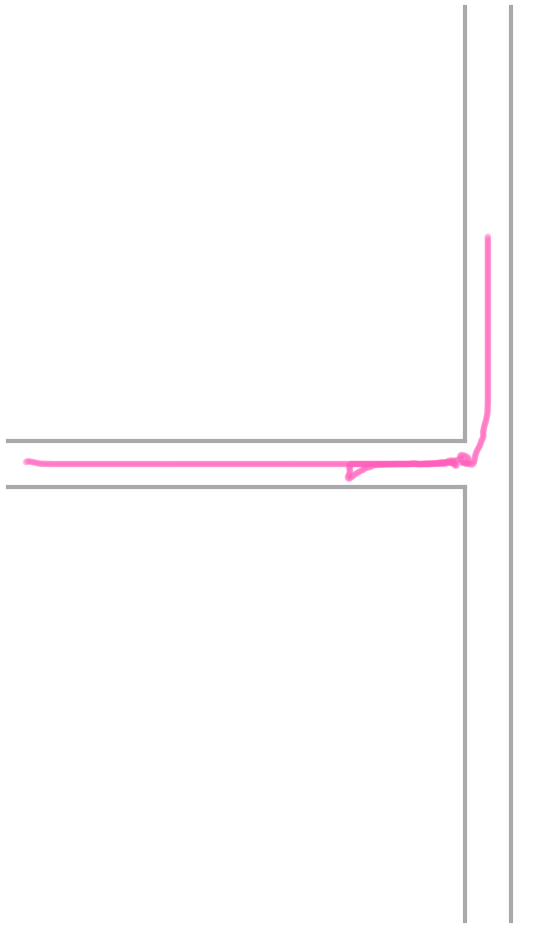

In [9]:
plotter = MA.Visualiser(agent_CT)
seed = random_seeds[4]
ep = 6
#payload = results[seed]['episodes'][ep]
#hist = payload['history']
#plotter.plotEpTrajectory(hist=hist, starttime=hist['t'].iloc[0], endtime=hist['t'].iloc[-1])

meta = results[seed]['episode_logs'][ep]
plotter.plotEpTrajectory(hist=results[seed]['episodes'][ep]['history'], starttime=meta['t_start'], endtime=meta['t_end'])

### Example Trajectories (Overlayed)

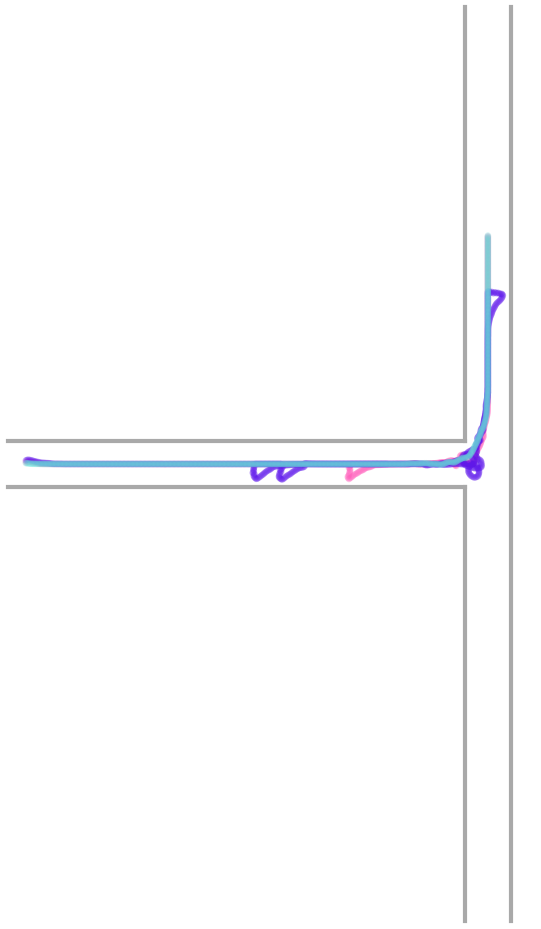

In [10]:
plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')
fig, ax = plotter.plotEpTrajectory(
    hist=results[seed]['episodes'][6]['history'],
    starttime=results[seed]['episode_logs'][6]['t_start'],
    endtime=results[seed]['episode_logs'][6]['t_end'],
    color='#ff5ebb'
)
fig, ax = plotter.plotEpTrajectory(
    fig=fig, ax=ax,
    hist=results[seed]['episodes'][7]['history'],
    starttime=results[seed]['episode_logs'][7]['t_start'],
    endtime=results[seed]['episode_logs'][7]['t_end'],
    color='#5e17eb'
)
fig, ax = plotter.plotEpTrajectory(
    fig=fig, ax=ax,
    hist=results[seed]['episodes'][8]['history'],
    starttime=results[seed]['episode_logs'][8]['t_start'],
    endtime=results[seed]['episode_logs'][8]['t_end'],
    color='#66dfd8'
)
#plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/ExampleTrajectories.pdf", transparent=True)
plt.show()

### Animate Trajectory as GIF

In [152]:
plotter = MA.Visualiser(agent_CT)
seed1 = random_seeds[3]
#seed2 = random_seeds[1]
#seed3 = random_seeds[2]

#plotter.animateEpTrajectory(hist=results[seed1]['episodes'][2]['history'], 
#                            starttime=results[seed1]['episode_logs'][2]['t_start'], 
#                            endtime=results[seed1]['episode_logs'][2]['t_end'], 
#                            speedup=6, fps=24,
#                          save_path='trajectory.gif')

plotter.animateEpTrajectory(hist=results[seed1]['episodes'][4]['history'], 
                            hist_id=-1,
                            starttime=results[seed1]['episode_logs'][4]['t_start'], 
                            endtime=results[seed1]['episode_logs'][4]['t_end'], 
                            speedup=6.0, fps=24,
                            trail_length=None, save_path='trajectoryNew.gif',
                            color='#ff5ebb', agentSize=0.15, trailAlpha=0.3,
                            showGoal=True, dpi=100)

Saved animation to trajectoryNew.gif


'trajectoryNew.gif'

## Seqnmf Sequenciness Analysis

### Spike times/ids → binned matrix

seqNMF needs a dense `(neurons × time)` matrix, not spike time/id lists. Bins spikes (default 5 ms, fine enough to resolve structure within a 100 ms theta cycle) and optionally smooths each neuron's binned trace.

In [175]:
#%autoreload 0
from seqnmf import seqnmf, plot

def spikes_to_matrix(times, ids, bin_size=0.005, t_start=None, t_stop=None,
                      smooth_sigma=1.0):
    times = np.asarray(times, dtype=float)
    ids = np.asarray(ids)

    if len(times) == 0:
        raise ValueError("No spikes provided for this times/ids pair.")

    if t_start is None:
        t_start = times.min()
    if t_stop is None:
        t_stop = times.max()

    neuron_ids = np.unique(ids)
    id_to_row = {nid: i for i, nid in enumerate(neuron_ids)}

    bin_edges = np.arange(t_start, t_stop + bin_size, bin_size)
    n_bins = len(bin_edges) - 1

    X = np.zeros((len(neuron_ids), n_bins))
    rows = np.array([id_to_row[i] for i in ids])
    bin_idx = np.digitize(times, bin_edges) - 1
    valid = (bin_idx >= 0) & (bin_idx < n_bins)
    np.add.at(X, (rows[valid], bin_idx[valid]), 1)

    if smooth_sigma is not None:
        from scipy.ndimage import gaussian_filter1d
        X = gaussian_filter1d(X, sigma=smooth_sigma, axis=1)

    return X, neuron_ids, bin_edges

/Users/liviastein/STDP_Theta-1/.venv/lib/python3.12/site-packages/seqnmf/__init__.py:5: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


### Fit seqNMF to CA1

`L` is derived from your 10 Hz theta frequency (100 ms → bins). `K=1` because you only expect one sequence type (forward sweeps).

In [170]:
THETA_FREQ_HZ = 10.0
THETA_CYCLE_MS = 1000.0 / THETA_FREQ_HZ  # = 100 ms

def run_seqnmf_on_CA1(ca1_spikedata, bin_size=0.005, K=1, Lambda=0.001,
                       smooth_sigma=1.0, seed=0):
    X, neuron_ids, bin_edges = spikes_to_matrix(
        ca1_spikedata['times'], ca1_spikedata['ids'],
        bin_size=bin_size, smooth_sigma=smooth_sigma
    )

    L = max(2, int(round((THETA_CYCLE_MS / 1000.0) / bin_size)))

    np.random.seed(seed)
    W, H, cost, loadings, power = seqnmf(X, K=K, L=L, Lambda=Lambda)

    return dict(X=X, W=W, H=H, cost=cost, loadings=loadings, power=power,
                neuron_ids=neuron_ids, bin_edges=bin_edges, L=L)

### Shuffle control

Circularly shifts each neuron's spike train independently — preserves each cell's own rate/ISI statistics but destroys consistent cross-neuron timing. Used as a null for the pooled (Option A) fit.

In [171]:
def circular_shift_shuffle(times, ids, t_start=None, t_stop=None, seed=0):
    rng = np.random.default_rng(seed)
    times = np.asarray(times, dtype=float)
    ids = np.asarray(ids)

    if t_start is None:
        t_start = times.min()
    if t_stop is None:
        t_stop = times.max()
    duration = t_stop - t_start

    shuffled = times.copy()
    for nid in np.unique(ids):
        mask = ids == nid
        shift = rng.uniform(0, duration)
        shuffled[mask] = t_start + ((times[mask] - t_start + shift) % duration)

    return shuffled, ids

### Compare conditions (theta / notheta / scrambled), with shuffle null

In [172]:
def compare_conditions_CA1(spikedata_by_condition, bin_size=0.005, K=1,
                            Lambda=0.001, n_shuffles=20, verbose=True):
    out = {}

    for cond, data in spikedata_by_condition.items():
        ca1_data = data['CA1']

        real = run_seqnmf_on_CA1(ca1_data, bin_size=bin_size, K=K, Lambda=Lambda)

        shuffle_powers = []
        for s in range(n_shuffles):
            sh_times, sh_ids = circular_shift_shuffle(
                ca1_data['times'], ca1_data['ids'], seed=s
            )
            sh_result = run_seqnmf_on_CA1(
                {'times': sh_times, 'ids': sh_ids},
                bin_size=bin_size, K=K, Lambda=Lambda, seed=s
            )
            shuffle_powers.append(sh_result['power'])

        shuffle_powers = np.array(shuffle_powers)
        z = (real['power'] - shuffle_powers.mean()) / (shuffle_powers.std() + 1e-12)

        out[cond] = dict(
            real_power=real['power'],
            shuffle_powers=shuffle_powers,
            z_score=z,
            seqnmf_result=real,
        )

        if verbose:
            print(f"CA1 / {cond:10s}: power={real['power']:.3f}  "
                  f"shuffle={shuffle_powers.mean():.3f}+/-{shuffle_powers.std():.3f}  "
                  f"z={z:.2f}")

    return out

### Extract usable spike data from `results` dict  

Looking at `TaskEpisode` loop: `agent_ST2.spikedata_by_condition` is reset only once per **seed**, before the episode loop starts — not between episodes. So each episode's saved payload (`results[seed]['episodes'][ep]['spikedata_by_condition']`) isn't isolated to that episode; it's **cumulative**, containing every spike since the start of that seed, through and including episode `ep`.

That's actually convenient, because two things are already sitting in your data with zero extra simulation work:

- **Pooled / whole-session view, for free.** `results[seed]['episodes'][-1]['spikedata_by_condition']` (the *last* episode's payload) already *is* the full accumulated session for that seed.
- **Isolated per-episode view, recoverable post-hoc.** Since the underlying lists are append-only and chronologically ordered, episode `k`'s own spikes are exactly the new entries beyond where episode `k-1` left off — recoverable by diffing consecutive payloads.

In [173]:
def extract_isolated_episode_spikedata(seed_episodes):
    """
    seed_episodes : results[seed]['episodes'] -- list of payload dicts
                    whose 'spikedata_by_condition' is CUMULATIVE within
                    the seed (each entry = everything since the start
                    of the seed, through that episode).

    Returns a list of the same length, but with each entry containing
    ONLY that episode's own spikes, reconstructed by diffing consecutive
    cumulative snapshots. No changes to TaskEpisode needed.
    """
    conditions = ('theta', 'notheta', 'scrambled')
    regions = ('CA1', 'CA3')

    isolated = []
    prev_len = {cond: {region: 0 for region in regions} for cond in conditions}

    for i, ep_payload in enumerate(seed_episodes):
        cumulative = ep_payload['spikedata_by_condition']
        episode_only = {cond: {} for cond in conditions}

        for cond in conditions:
            for region in regions:
                times = cumulative[cond][region]['times']
                ids = cumulative[cond][region]['ids']
                start = prev_len[cond][region]

                if len(times) < start:
                    raise RuntimeError(
                        f"Episode {i}, {cond}/{region}: spike list shrank "
                        f"({len(times)} < {start}). spikedata may be getting "
                        f"reset somewhere unexpected -- this diffing approach "
                        f"assumes append-only, monotonically growing lists."
                    )

                episode_only[cond][region] = {
                    'times': times[start:],
                    'ids': ids[start:],
                }
                prev_len[cond][region] = len(times)

        isolated.append(episode_only)

    return isolated

### Option A — pooled (whole-session) fit, per seed

Uses the last episode's payload directly (already the full-session accumulation), with a shuffle null.

In [178]:
import time

# Benchmark a single episode fit
sample_ep = results[random_seeds[0]]['episodes'][0]['spikedata_by_condition']['theta']['CA1']
print(f"Episode: {len(np.unique(sample_ep['ids']))} CA1 cells, "
      f"~{int((max(sample_ep['times'])-min(sample_ep['times']))/0.005)} time bins")
t0 = time.time()
_ = run_seqnmf_on_CA1(sample_ep, bin_size=0.005, K=1, Lambda=0.001)
print(f"Single episode fit: {time.time()-t0:.2f}s")

# Benchmark the pooled (full-session) fit
pooled_ca1 = results[random_seeds[0]]['episodes'][-1]['spikedata_by_condition']['theta']['CA1']
print(f"Pooled: {len(np.unique(pooled_ca1['ids']))} CA1 cells, "
      f"~{int((max(pooled_ca1['times'])-min(pooled_ca1['times']))/0.005)} time bins")
t0 = time.time()
_ = run_seqnmf_on_CA1(pooled_ca1, bin_size=0.005, K=1, Lambda=0.001)
print(f"Single pooled fit: {time.time()-t0:.2f}s")

Episode: 72 CA1 cells, ~9486 time bins
Single episode fit: 11.45s
Pooled: 74 CA1 cells, ~116546 time bins
Single pooled fit: 147.19s


In [179]:
SEED = random_seeds[0]  # pick a seed to inspect; loop over random_seeds for all of them

pooled_spikedata_by_condition = results[SEED]['episodes'][-1]['spikedata_by_condition']

t0 = time.time()
pooled_results = compare_conditions_CA1(
    pooled_spikedata_by_condition,
    bin_size=0.005, K=1, Lambda=0.001, n_shuffles=0   # fast: visualization only, no null
)
print(f"Option A (visualization-only) took {time.time()-t0:.1f}s")

CA1 / theta     : power=0.100  shuffle=nan+/-nan  z=nan
CA1 / notheta   : power=0.068  shuffle=nan+/-nan  z=nan
CA1 / scrambled : power=0.079  shuffle=nan+/-nan  z=nan
Option A (visualization-only) took 422.5s


### Option B — per-episode fits, aggregated across episodes and seeds

Fits each episode/condition once (no shuffle here — across 5 seeds × 10 episodes × 3 conditions × shuffles would mean over a thousand fits for not much benefit). Instead, since each episode gives matched theta/notheta/scrambled values, a **paired comparison across episodes** (Wilcoxon signed-rank) is used — statistically more appropriate here anyway, since these are real repeated measures rather than synthetic shuffle replicates.

Very short episodes (e.g. an early wrong-arm trial) are skipped since they won't have enough spikes/cycles for a stable fit.

In [180]:
MIN_DURATION_S = 2.0
MIN_CA1_SPIKES = 50

t0 = time.time()
per_episode_rows = []

for seed in random_seeds:
    isolated = extract_isolated_episode_spikedata(results[seed]['episodes'])

    for ep, ep_spikedata in enumerate(isolated):
        duration = results[seed]['episode_logs'][ep]['duration']

        for cond in ('theta', 'notheta', 'scrambled'):
            ca1_data = ep_spikedata[cond]['CA1']
            if duration < MIN_DURATION_S or len(ca1_data['times']) < MIN_CA1_SPIKES:
                continue
            try:
                r = run_seqnmf_on_CA1(ca1_data, bin_size=0.005, K=1, Lambda=0.001)
            except ValueError:
                continue

            per_episode_rows.append({
                'seed': seed, 'episode': ep, 'condition': cond,
                'duration': duration, 'power': r['power'],
            })

per_episode_df = pd.DataFrame(per_episode_rows)
print(f"Option B took {time.time()-t0:.1f}s for {len(per_episode_df)} fits")
per_episode_df.groupby('condition')['power'].agg(['mean', 'std', 'count'])

Option B took 1464.0s for 150 fits


,mean,std,count
condition,,,
notheta,0.078265,0.013473,50
scrambled,0.090194,0.016241,50
theta,0.112503,0.012611,50


In [181]:
# Paired comparison across episodes (only episodes with all 3 conditions present)
pivot = per_episode_df.pivot_table(index=['seed', 'episode'], columns='condition', values='power')
pivot = pivot.dropna()
print(f"n episodes with all 3 conditions: {len(pivot)}")
print(pivot.describe())

if len(pivot) >= 5:  # Wilcoxon needs a reasonable n
    w1, p1 = stats.wilcoxon(pivot['theta'], pivot['scrambled'])
    print(f"\ntheta vs scrambled: Wilcoxon W={w1:.2f}, p={p1:.4f}")
    w2, p2 = stats.wilcoxon(pivot['theta'], pivot['notheta'])
    print(f"theta vs notheta:   Wilcoxon W={w2:.2f}, p={p2:.4f}")
else:
    print("Too few matched episodes for a Wilcoxon test -- run more episodes/seeds.")

n episodes with all 3 conditions: 50
condition    notheta  scrambled      theta
count      50.000000  50.000000  50.000000
mean        0.078265   0.090194   0.112503
std         0.013473   0.016241   0.012611
min         0.065669   0.071464   0.097179
25%         0.067502   0.078466   0.103804
50%         0.072463   0.084553   0.106782
75%         0.089210   0.103087   0.120339
max         0.125507   0.152338   0.161294

theta vs scrambled: Wilcoxon W=0.00, p=0.0000
theta vs notheta:   Wilcoxon W=0.00, p=0.0000


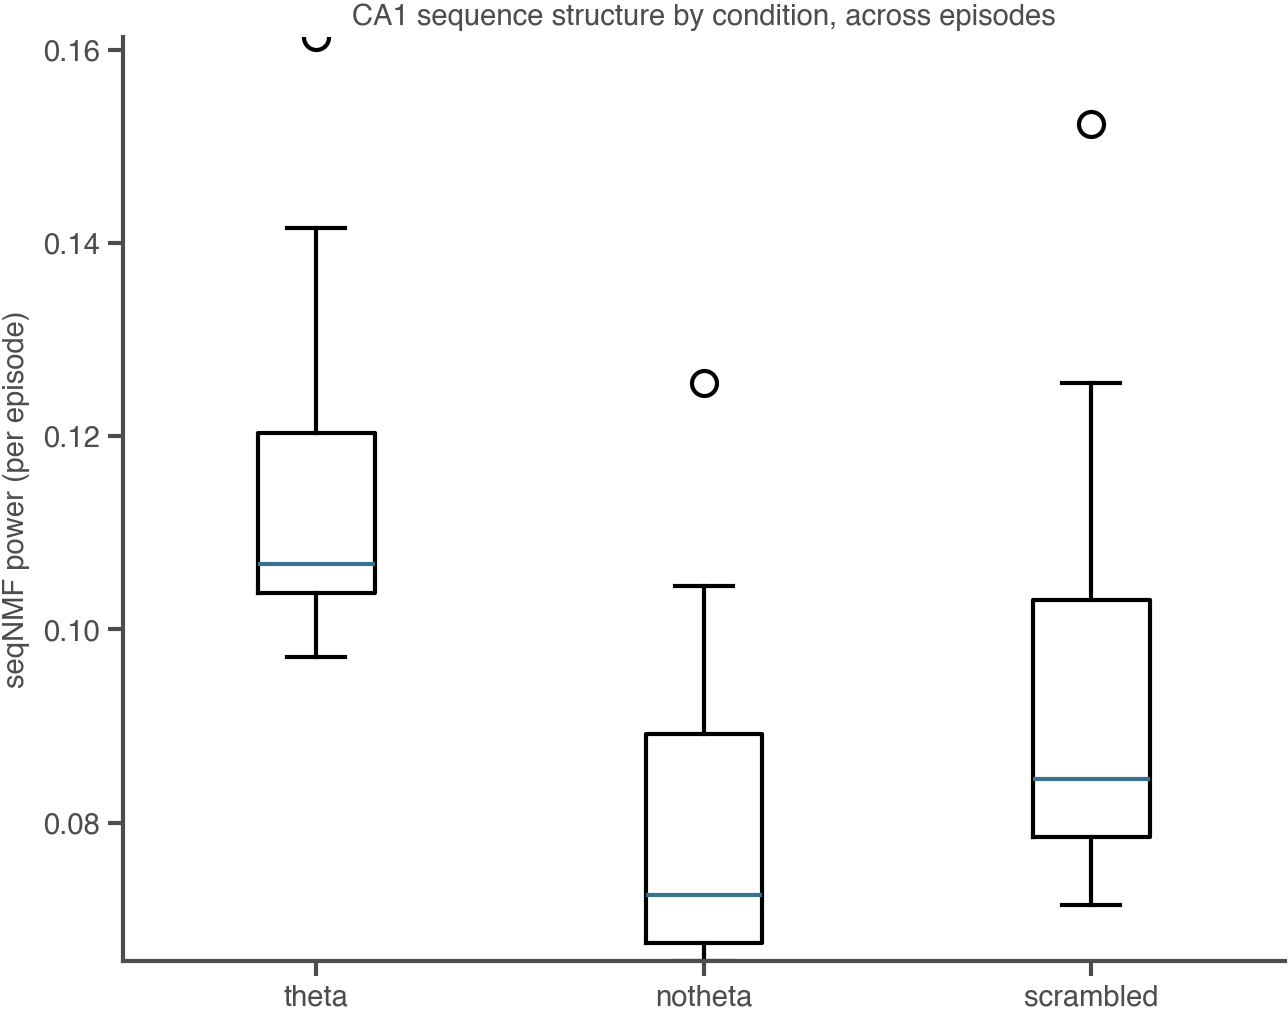

In [182]:
plt.figure(figsize=(5, 4))
order = ['theta', 'notheta', 'scrambled']
data_for_box = [per_episode_df.loc[per_episode_df['condition'] == c, 'power'].values for c in order]
plt.boxplot(data_for_box, labels=order)
plt.ylabel('seqNMF power (per episode)')
plt.title('CA1 sequence structure by condition, across episodes')
plt.show()

### Visualize the discovered sequence (pooled example, theta condition)

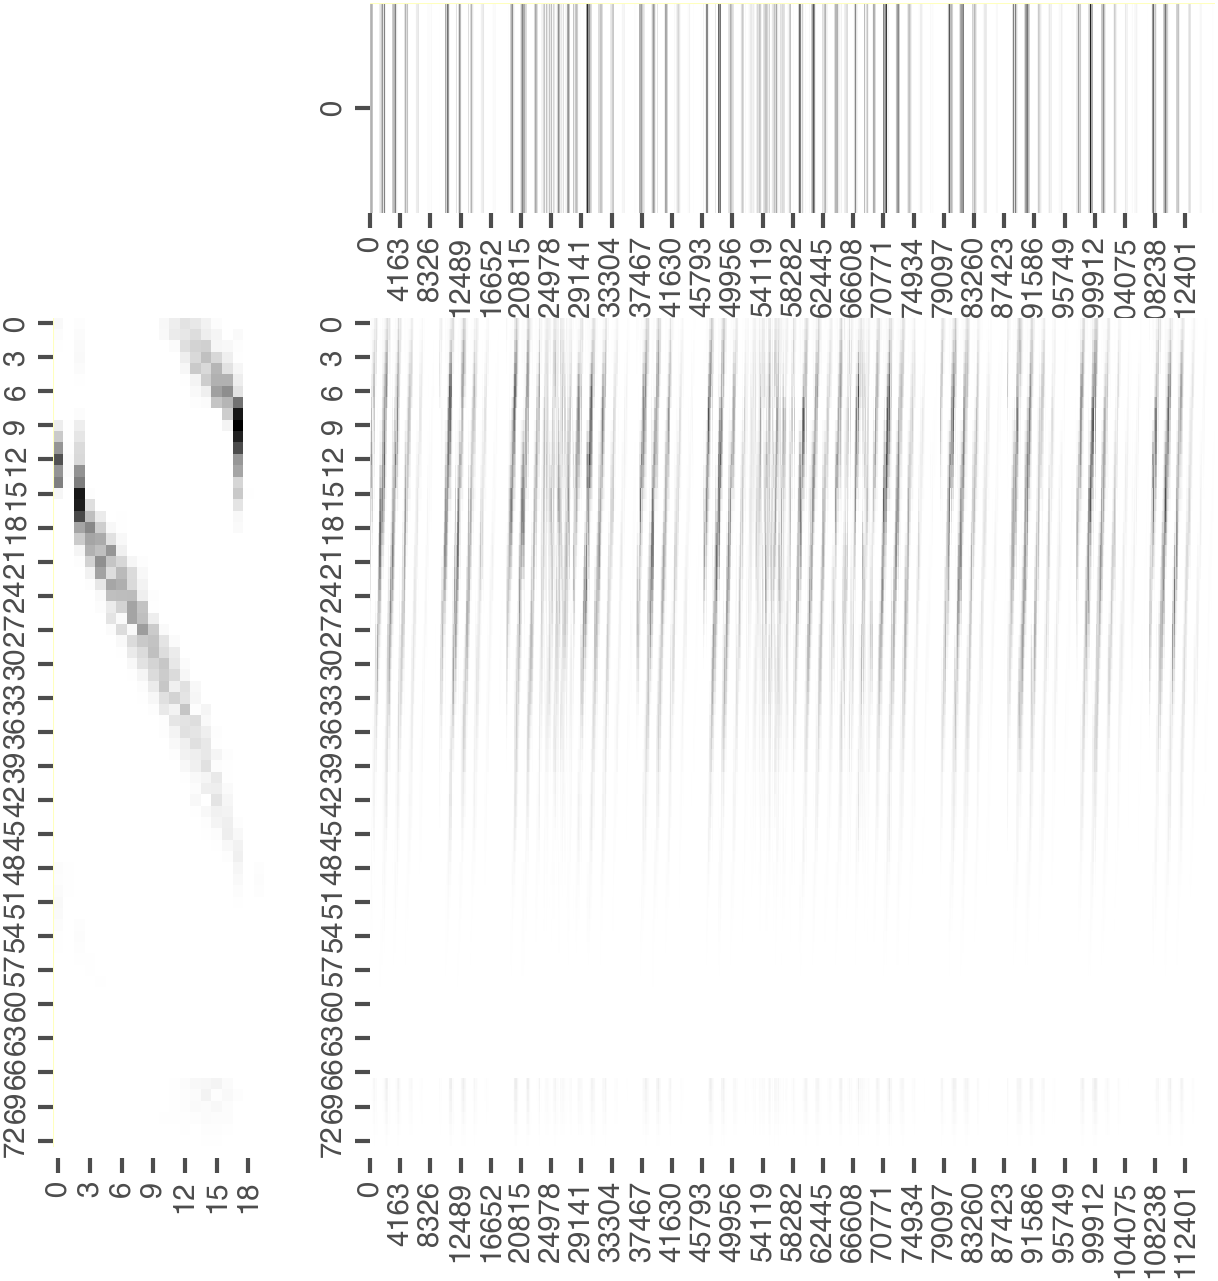

In [183]:
r = pooled_results['theta']['seqnmf_result']
plot(r['W'], r['H'])
plt.show()

### Compare z-scores across conditions (pooled edition)

In [ ]:
conditions = list(pooled_results.keys())
z_scores = [pooled_results[c]['z_score'] for c in conditions]

plt.figure(figsize=(5, 4))
plt.bar(conditions, z_scores, color=['#4C72B0', '#DD8452', '#55A868'])
plt.axhline(0, color='k', lw=0.8)
plt.ylabel('z-score (real vs. shuffle power)')
plt.title(f'CA1 sequence structure by condition (pooled, seed={SEED})')
plt.show()

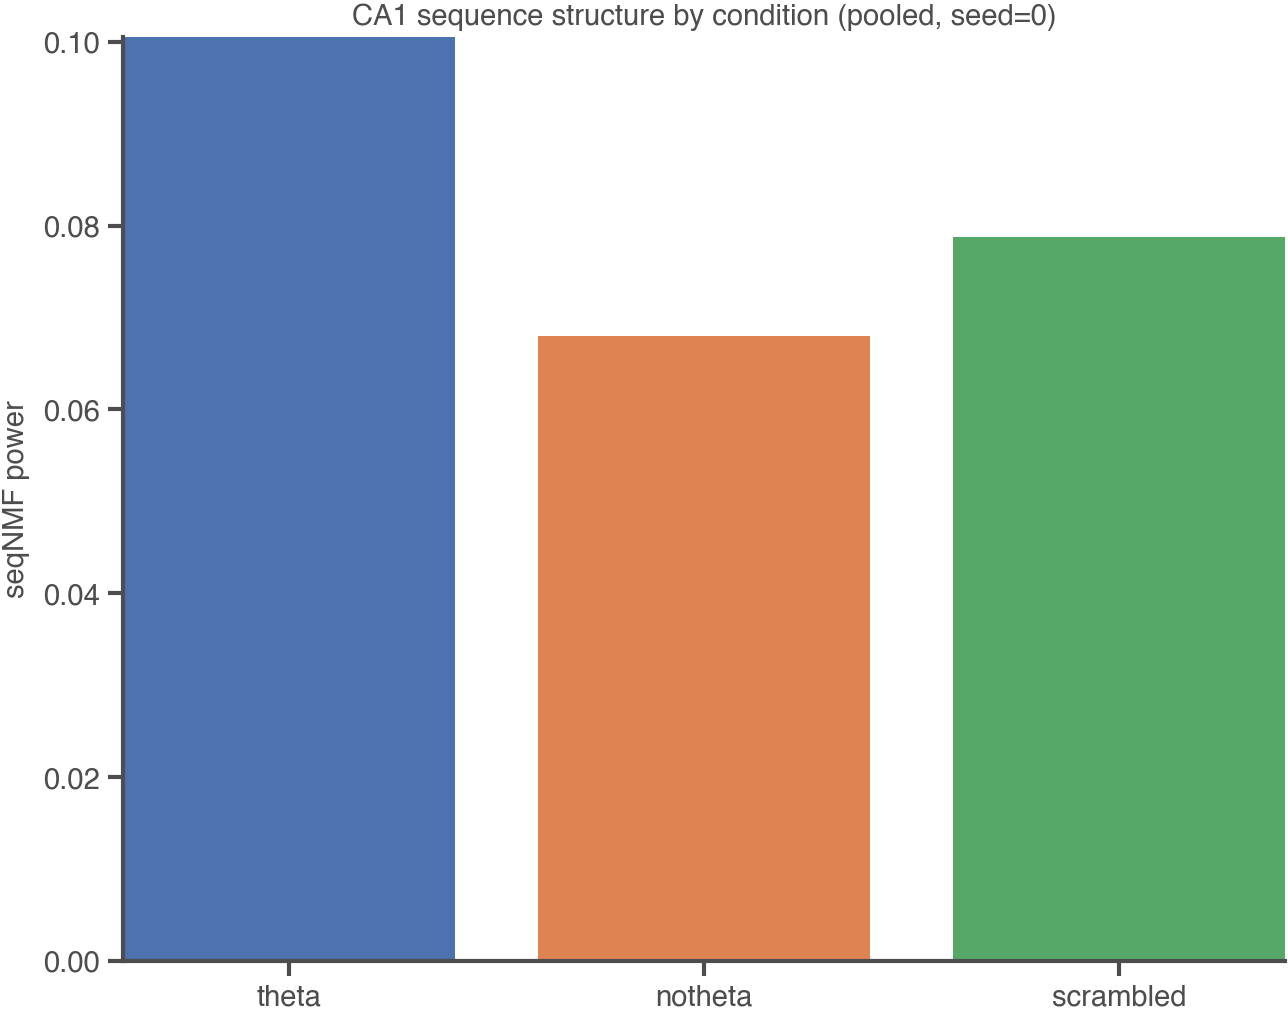

In [184]:
conditions = list(pooled_results.keys())
powers = [pooled_results[c]['real_power'] for c in conditions]

plt.figure(figsize=(5, 4))
plt.bar(conditions, powers, color=['#4C72B0', '#DD8452', '#55A868'])
plt.ylabel('seqNMF power')
plt.title(f'CA1 sequence structure by condition (pooled, seed={SEED})')
plt.show()

In [189]:
# place feld centres for each neuron in the order of neuron_ids

place_field_peak = agent_CT.centres 
sort_order = np.argsort([place_field_peak[nid] for nid in r['neuron_ids']])
W_sorted = r['W'][sort_order, :, :]
plot(W_sorted, r['H'])
plt.show()

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 0, the array at index 0 has size 2 and the array at index 1 has size 1

### Plot the performance results

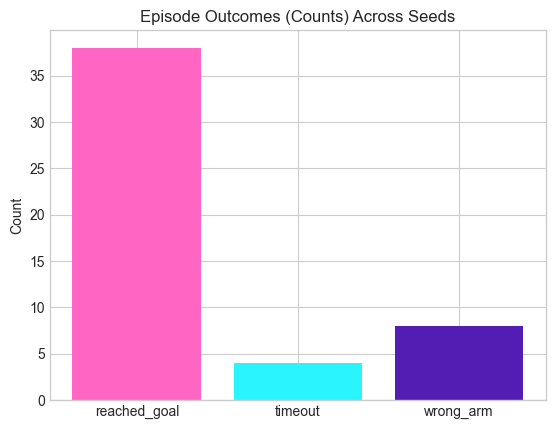

In [113]:
# bar plot with outcomes across seeds as counts
# use specific style for plot
plt.style.use('seaborn-v0_8-whitegrid')
# define own color palette with colour keys
Livi_palette = ['#ff66c4', '#2AF5FF', '#531CB3']

summary_df = pd.DataFrame(summary)
labels = ['reached_goal', 'timeout', 'wrong_arm']
counts = [
    int(summary_df['reached_goal'].sum()),
    int(summary_df['timeouts'].sum()),
    int(summary_df['wrong_arm'].sum())
 ]
x = np.arange(len(labels))

fig, ax = plt.subplots()
bars = ax.bar(x, counts, color= Livi_palette)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Count')
ax.set_title('Episode Outcomes (Counts) Across Seeds')

plt.show()

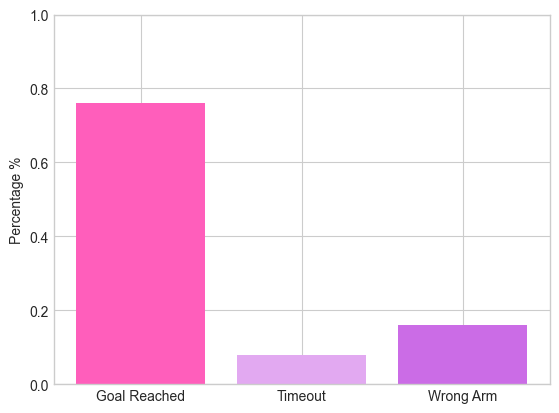

In [135]:
# bar plot with outcomes across seeds as percentages: e.g. timout/total episodes etc
# use specific style for plot
plt.style.use('seaborn-v0_8-whitegrid')
# define own color palette with colour keys
#Livi_palette1 = ['#ff66c4', '#2AF5FF', '#531CB3']
Livi_palette = {
    "türkis": '#66dfd8',
    "lBlue": '#1097d3',
    "dViolet": '#5e17eb',
    "lpurple": '#8c52ff',
    "altRosa": '#cb6ce6',
    "lRosa": '#e2a9f1',
    "pink": '#ff5ebb'
}

#summary_df = pd.DataFrame(summary)
labels = ['Goal Reached', 'Timeout', 'Wrong Arm']
total_episodes = sum(s['total_episodes'] for s in summary)
reached = sum(s['reached_goal'] for s in summary)
timeouts = sum(s['timeouts'] for s in summary)
wrong_arm = sum(s['wrong_arm'] for s in summary)
percentages = [reached/total_episodes, timeouts/total_episodes, wrong_arm/total_episodes] if total_episodes>0 else [np.nan]*3

#total_episodes = summary_df['total_episodes'].sum()
#percentages = [
    #float(summary_df['reached_goal'].sum()) / total_episodes if total_episodes > 0 else np.nan,
    #float(summary_df['timeouts'].sum()) / total_episodes if total_episodes > 0 else np.nan,
    #float(summary_df['wrong_arm'].sum()) / total_episodes if total_episodes > 0 else np.nan
#]
x = np.arange(len(labels))
fig, ax = plt.subplots()
bars = ax.bar(x, percentages, color= [Livi_palette['pink'], Livi_palette['lRosa'], Livi_palette['altRosa']])
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Percentage %')
# set limit for y axis to 0-100%
ax.set_ylim(0, 1)
#plt.suptitle('Episode Outcomes (Percentages) Across 50 Seeds', fontsize=14, fontweight='bold')
# add subtitle with theta condition and number of episodes in italics
#ax.set_title(f"STDP Learning with Clean Theta - {total_episodes} Episodes per Seed", fontsize=10, fontstyle='italic', loc='center')

plt.show()
 

per-seed successful counts: {0: 7, 2: 7, 4: 7, 6: 9, 42: 8}
sum of per-seed successful counts: 38
summary total_reached_goal (from seed summaries): 38


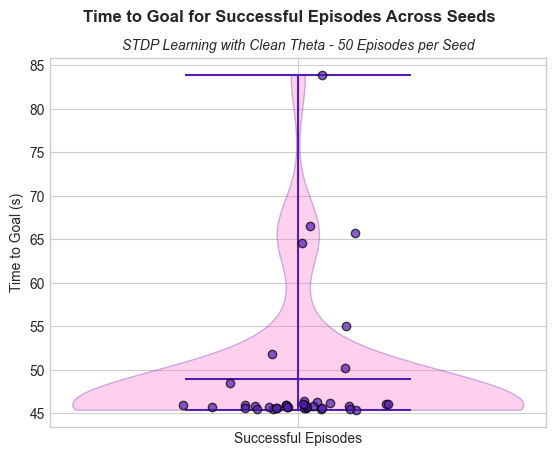

In [123]:
# create violin plot of time to goal for successful episodes across seeds
plt.style.use('seaborn-v0_8-whitegrid')
# define own color palette with colour keys
Livi_palette = ['#ff66c4', '#2AF5FF', '#531CB3']
total_episodes = sum(s['total_episodes'] for s in summary)
# debug: per-seed successful counts (from `results`)
success_counts = {
    seed: sum(1 for log in data['episode_logs'] if log.get('outcome', {}).get('reward_count', 0) > 0)
    for seed, data in results.items()
}
print('per-seed successful counts:', success_counts)
print('sum of per-seed successful counts:', sum(success_counts.values()))
print('summary total_reached_goal (from seed summaries):', sum(s['reached_goal'] for s in summary))

# collect per-episode durations for successful episodes (reward_count > 0)
successful_times = [
    log['duration']
    for seed, data in results.items()
    for log in data['episode_logs']
    if log.get('outcome', {}).get('reward_count', 0) > 0
]

# convert to numpy array for plotting (optional)
successful_times = np.array(successful_times)

fig, ax = plt.subplots()
ax.violinplot(successful_times, showmeans=True, showmedians=False, showextrema=True)
# set face colour and edge colour of the violin plot
for body in ax.collections:
    try:
        body.set_facecolor(Livi_palette[0])
        body.set_edgecolor(Livi_palette[2])
    except Exception:
        pass

# scatter actual data points from episodes on top of violin plot and spread them a bit horizontally
x = np.random.normal(1, 0.04, size=len(successful_times))  # spread around x=1 with small random noise
ax.scatter(x, successful_times, color=Livi_palette[2], alpha=0.7, edgecolor='k', zorder=2)

# set y-limits sensibly
if len(successful_times) > 0:
    ymin = max(0, successful_times.min() - 2)
    ymax = successful_times.max() + 2
    ax.set_ylim(ymin, ymax)
else:
    ax.set_ylim(0, 1)

ax.set_xticks([1])
ax.set_xticklabels(['Successful Episodes'])
ax.set_ylabel('Time to Goal (s)')
plt.suptitle('Time to Goal for Successful Episodes Across Seeds', fontsize=12, fontweight='bold')
ax.set_title(f"STDP Learning with Clean Theta - {total_episodes} Episodes per Seed", fontsize=10, fontstyle='italic', loc='center')
plt.show()

In [110]:
print(len(successful_times))

10


### Heatmap of agent trajectories across seeds
Rerun seeds to plot!

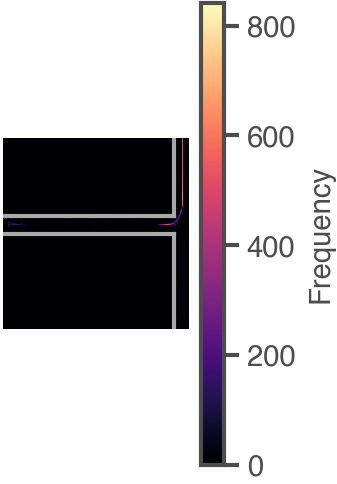

In [63]:
all_positions = []
for seed, data in results.items():
    for episode_payload in data['episodes']:
        history = episode_payload['history']
        if 'pos' in history.columns and len(history) > 0:
            pos = np.vstack(history['pos'].to_numpy())
            all_positions.append(pos)

all_positions = np.vstack(all_positions)

#fig, ax = plt.subplots(figsize=(15, 5))
plotter = MA.Visualiser(agent_CT)
fig, ax = plotter.plotMazeStructure(fig=None, ax=None)
#plotter.plotMazeStructure(fig=fig, ax=ax)

h = ax.hist2d(all_positions[:, 0], all_positions[:, 1], bins=280, cmap='magma', alpha=1)
plt.colorbar(h[3], ax=ax, label='Frequency') 
plt.show()

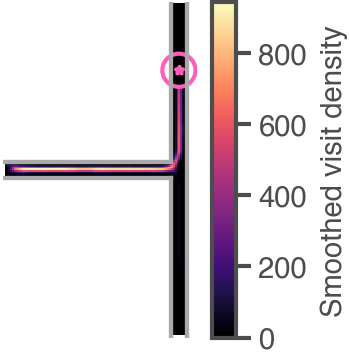

In [66]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
#from scipy.ndimage import gaussian_filter
import numpy as np

plt.style.use('/Users/liviastein/STDP_Theta-1/ResultPipelines/plot_style.mplstyle')

rs = agent_CT.roomSize
hw = 0.05 * rs
arm_w = 2 * hw

# draw maze and record extents
fig, ax = plotter.plotMazeStructure(fig=None, ax=None)
xlim = ax.get_xlim()
ylim = ax.get_ylim()
ax.set_aspect('equal') 

#dx = dy = 0.01
#xedges = np.arange(xlim[0], xlim[1] + dx, dx)
#yedges = np.arange(ylim[0], 9.99 + dy, dy)
# compute 2D histogram over full maze extents
H, xedges, yedges = np.histogram2d(
    all_positions[:,0], all_positions[:,1],
    bins=[110, 200], range=[[xlim[0], xlim[1]], [ylim[0], 9.99]]
)

# mask values outside of the maze walls by creating a mask
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
X, Y = np.meshgrid(xc, yc, indexing="ij") # create grid of coordinates for histogram bins

# define mask for points inside the maze structure (i.e. within walls)
inside = (
    ((X >= 0) & (X <= rs) & (Y >= rs - hw) & (Y <= rs + hw)) |
    ((X >= rs) & (X <= rs + arm_w) & (Y >= 0) & (Y <= 2 * rs))
)

H_masked = np.ma.array(H, mask=~inside)
from scipy.ndimage import gaussian_filter

H_smooth = gaussian_filter(H, sigma=1)
H_masked = np.ma.array(H_smooth, mask=(~inside))

cmap = plt.cm.magma.copy() # copy the colormap
cmap.set_bad(alpha=0) # make masked values transparent

# show with imshow (transpose H so axes match), keep extent = full maze
#extent = agent_CT.extent
extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
#im = ax.imshow(H_smooth.T, origin='lower', extent=extent, cmap='magma', alpha=1, zorder=0, aspect='auto')
im = ax.imshow(H_masked.T, origin='lower', extent=extent, cmap='magma', alpha=1, zorder=0, aspect='equal', interpolation='nearest')

# thin colorbar matching axis height
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="12%", pad=0.05)
fig.colorbar(im, cax=cax, label='Smoothed visit density')

# restore exact view and aspect, and redraw maze lines on top
ax.set_xlim(xlim); ax.set_ylim(ylim)
ax.set_aspect('equal') 
plotter.plotMazeStructure(fig=fig, ax=ax)   # draws lines on top
plotter.plotGoal(fig=fig, ax=ax)   # draw goal on top of maze structure

plt.savefig("/Users/liviastein/STDP_Theta-1/Final_Figures/TrajectoryHM_IntactNew.png", transparent=True)
#plt.tight_layout()
plt.show()

ValueError: points have dimension 22000, dataset has dimension 2

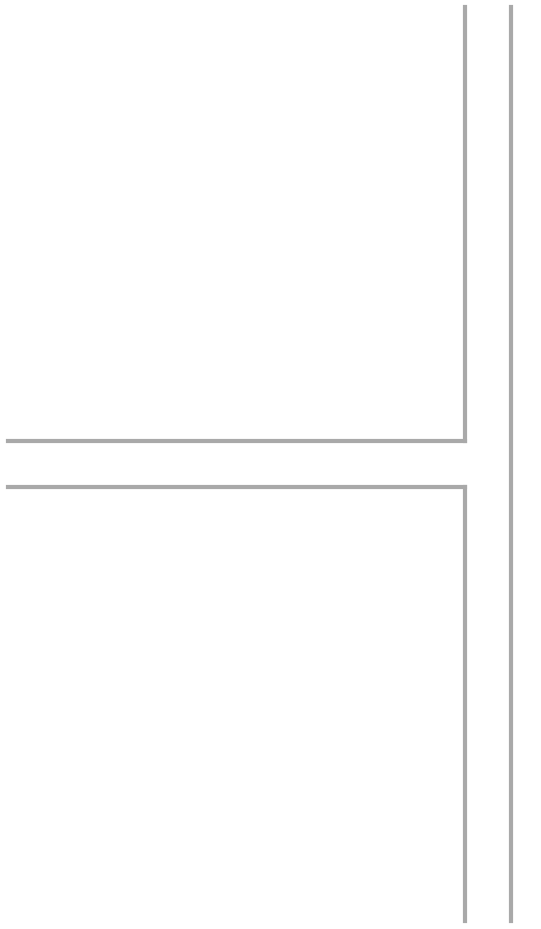

In [132]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
#from scipy.ndimage import gaussian_filter
import numpy as np

rs = agent_CT.roomSize
hw = 0.05 * rs
arm_w = 2 * hw

# draw maze and record extents
fig, ax = plotter.plotMazeStructure(fig=None, ax=None)
x_grid = np.linspace(0, 5.5, 110)
y_grid = np.linspace(0, 10, 200)

X,Y = np.meshgrid(x_grid, y_grid)

from scipy import ndimage
from scipy.stats import gaussian_kde
kde = gaussian_kde(all_positions.T, bw_method=0.5)

Z = kde(np.vstack([X.ravel(), Y.ravel()]).T).reshape(X.shape)

#dx = dy = 0.01
#xedges = np.arange(xlim[0], xlim[1] + dx, dx)
#yedges = np.arange(ylim[0], 9.99 + dy, dy)
# compute 2D histogram over full maze extents
H, xedges, yedges = np.histogram2d(
    all_positions[:,0], all_positions[:,1],
    bins=150, range=[[x_grid[0], x_grid[-1]], [y_grid[0], y_grid[-1]]]
)

# mask values outside of the maze walls by creating a mask
#xc = 0.5 * (xedges[:-1] + xedges[1:])
#yc = 0.5 * (yedges[:-1] + yedges[1:])
#X, Y = np.meshgrid(xc, yc, indexing="ij") # create grid of coordinates for histogram bins

# define mask for points inside the maze structure (i.e. within walls)
inside = (
    ((X >= 0) & (X <= rs) & (Y >= rs - hw) & (Y <= rs + hw)) |
    ((X >= rs) & (X <= rs + arm_w) & (Y >= 0) & (Y <= 2 * rs))
)

Z_masked = np.ma.array(Z, mask=~inside)

cmap = plt.cm.magma.copy() # copy the colormap
cmap.set_bad(alpha=0) # make masked values transparent

# show with imshow (transpose H so axes match), keep extent = full maze
#extent = agent_CT.extent
extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
#im = ax.imshow(H_smooth.T, origin='lower', extent=extent, cmap='magma', alpha=1, zorder=0, aspect='auto')
im = ax.imshow(Z_masked.T, origin='lower', extent=extent, cmap='magma', alpha=1, zorder=0, aspect='auto', interpolation='nearest')

# thin colorbar matching axis height
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="12%", pad=0.05)
fig.colorbar(im, cax=cax, label='Smoothed visit density')

# restore exact view and aspect, and redraw maze lines on top
ax.set_xlim(xlim); ax.set_ylim(ylim)
ax.set_aspect('equal') 
plotter.plotMazeStructure(fig=fig, ax=ax)   # draws lines on top
plotter.plotGoal(fig=fig, ax=ax)   # draw goal on top of maze structure

#plt.tight_layout()
plt.show()

### Summarise results in table for exporting

In [14]:
from pathlib import Path

theta_condition = "clean_theta"  # change this in each notebook
out_dir = Path("/Users/liviastein/STDP_Theta-1/ResultPipelines/summary_tables_K5_15")
out_dir.mkdir(parents=True, exist_ok=True)

rows = []
for seed, data in results.items():
    for log in data["episode_logs"]:
        outcome = log.get("outcome", {})
        if outcome.get("reward_count", 0) > 0:
            label = "reached_goal"
        elif outcome.get("wrong_arm_count", 0) > 0:
            label = "wrong_arm"
        elif outcome.get("timeout_count", 0) > 0:
            label = "timeout"
        else:
            label = "unknown"

        rows.append({
            "theta_condition": theta_condition,
            "seed": seed,
            "episode": log.get("episode"),
            "label": label,
            "duration": log.get("duration", np.nan),
            "reward_count": outcome.get("reward_count", 0),
            "wrong_arm_count": outcome.get("wrong_arm_count", 0),
            "timeout_count": outcome.get("timeout_count", 0),
        })

episode_table = pd.DataFrame(rows)

seed_summary_table = (
    episode_table.groupby(["theta_condition", "seed"], as_index=False)
    .agg(
        total_episodes=("episode", "count"),
        reached_goal=("label", lambda s: int((s == "reached_goal").sum())),
        wrong_arm=("label", lambda s: int((s == "wrong_arm").sum())),
        timeouts=("label", lambda s: int((s == "timeout").sum())),
        percentage_correct=("label", lambda s: float((s == "reached_goal").sum()) / len(s) if len(s) > 0 else np.nan),
        average_time_to_goal=("duration", lambda s: float(s[episode_table.loc[s.index, "label"] == "reached_goal"].mean())
                              if (episode_table.loc[s.index, "label"] == "reached_goal").any() else np.nan),
    )
)

episode_table.to_csv(out_dir / f"{theta_condition}_episode_table.csv", index=False)
seed_summary_table.to_csv(out_dir / f"{theta_condition}_seed_summary_table.csv", index=False)

print(episode_table.head())
print("===============================")
print(seed_summary_table)

  theta_condition  seed  episode         label  duration  reward_count  \
0     clean_theta     0        0  reached_goal     47.47             1   
1     clean_theta     0        1  reached_goal     46.09             1   
2     clean_theta     0        2       timeout     90.01             0   
3     clean_theta     0        3  reached_goal     45.92             1   
4     clean_theta     0        4       timeout     90.01             0   

   wrong_arm_count  timeout_count  
0                0              0  
1                0              0  
2                0              1  
3                0              0  
4                0              1  
  theta_condition  seed  total_episodes  reached_goal  wrong_arm  timeouts  \
0     clean_theta     0              10             8          0         2   
1     clean_theta     2              10             7          1         2   
2     clean_theta     4              10            10          0         0   
3     clean_theta     6    

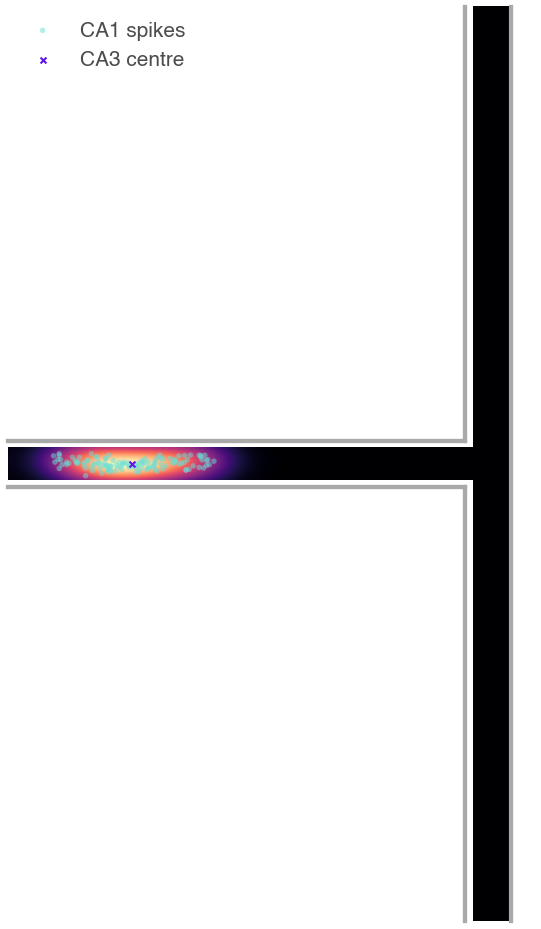

CA3 centre:        x=1.356
Mean spike x:      1.355
Median spike x:    1.328


In [30]:
# Plot spike positions directly on the maze — no binning, no transpose
fig, ax = plotter.plotMazeStructure(fig = None, ax = None)
neuron_id = 10
ep1        = results[seed]['episodes'][0] 
ep_times   = ep1['history']['t'].to_numpy(dtype=float)
ep_pos     = np.stack(ep1['history']['pos'].values).astype(float)
ep_ca1     = ep1['spikedata_by_condition']['theta']['CA1']
ep_spk_t   = np.asarray(ep_ca1['times'], dtype=float)
ep_spk_ids = np.asarray(ep_ca1['ids'], dtype=int)

mask       = (ep_spk_ids == neuron_id) & \
             (ep_spk_t >= ep_times.min()) & \
             (ep_spk_t <= ep_times.max())
ep1_spikes = ep_spk_t[mask]
spike_pos  = ep_pos[np.array([
    np.argmin(np.abs(ep_times - t)) for t in ep1_spikes # match spike times to positions within episode 1 only
])]

# Jitter in y direction so kde works properly and we get a field -> chenage to jitter in x direction when plotting place fields in maze arms to prevent artificial enlongation of fields in y direction!!
np.random.seed(0)  # for reproducibility
jitter_std = 0.05   # small relative to corridor width
spike_pos_jittered = spike_pos.copy()
spike_pos_jittered[:, 1] += np.random.normal(0, jitter_std, size=len(spike_pos))

# raw spike dots — no heatmap, no transpose, ground truth
ax.scatter(spike_pos_jittered[:, 0], spike_pos_jittered[:, 1], # spike_pos[:, 0] is x, spike_pos[:, 1] is y
          c='#66dfd8', s=6.9, zorder=3, label='CA1 spikes', marker='.', edgecolor='none', lw=0, alpha=0.5)
ax.scatter(*centres[neuron_id], c='#5e17eb', s=2, # * 
           marker='x', zorder=4, label='CA3 centre')

# add heatmap of spike density for visualisation (optional)
from scipy import ndimage
from scipy.stats import gaussian_kde # kde is a non-parametric way to estimate the probability density function of a random variable, in this case the spatial density of spikes
kde = gaussian_kde(spike_pos_jittered.T, bw_method=0.5) # fit kde to spike positions which means we are treating spike positions as samples from an underlying spatial distribution and want to estimate the density of that distribution across the maze. We transpose spike_pos to get shape (2, n_spikes) which is what gaussian_kde expects for 2D data.
#
# grid should should cover the entire maze area and not only spike positions. so we should consider maze boundaries, NOT spike positions
x_grid = np.linspace(0, 5.5, 110) # maze boundaries in x
y_grid = np.linspace(0, 10, 200) #maze boundaries in y 
#x_grid = np.linspace(ep_pos[:,0].min(), ep_pos[:,0].max(), 100)
#y_grid = np.linspace(ep_pos[:,1].min(), ep_pos[:,1].max(), 100)
X, Y = np.meshgrid(x_grid, y_grid)
Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)

# add a filter so there is some smoothing to the heatmap, e.g. gaussian filter
Z = ndimage.gaussian_filter(Z, sigma=3) # ndimage

# TMaze geometry
rs = agent_CT.roomSize
hw = 0.05 * rs
arm_w = 2 * hw

inside = (
    ((X >= 0) & (X <= rs) & (Y >= rs - hw) & (Y <= rs + hw)) |
    ((X >= rs) & (X <= rs + arm_w) & (Y >= 0) & (Y <= 2 * rs))
)

# if you smooth first, re-apply the mask afterwards
masked_field = np.ma.array(Z, mask=~inside)

ax.imshow(masked_field, origin='lower', interpolation='gaussian', extent=[x_grid.min(), x_grid.max(), y_grid.min(), y_grid.max()], cmap='magma', alpha=1.0, zorder=2)
ax.legend(frameon=False, fontsize=5)
#ax.set_title(f'Neuron {neuron_id} — raw spike positions ep1')
plotter.plotMazeStructure(fig=fig, ax=ax) # overlay maze structure for context
#plotter.plotGoal(fig = fig, ax=ax)
#plt.savefig(f"/Users/liviastein/STDP_Theta-1/Final_Figures/PlaceField_Neuron{neuron_id}wSpikesK5Intact.pdf", transparent = True)
plt.show()

print(f"CA3 centre:        x={centres[neuron_id][0]:.3f}")
print(f"Mean spike x:      {spike_pos[:,0].mean():.3f}")
print(f"Median spike x:    {np.median(spike_pos[:,0]):.3f}")

In [ ]:
from pathlib import Path
import joblib
import copy

checkpoint_dir = Path("/Users/liviastein/STDP_Theta-1/ResultPipelines/checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

analysis_state = {
    "results": results,
    "summary": summary,
    "episode_table": episode_table,
    "seed_summary_table": seed_summary_table,
    "random_seeds": random_seeds,
    "params": params,
    "theta_condition": theta_condition,
    "maze_walls": copy.deepcopy(agent_CT.walls),
    "maze_state": copy.deepcopy(agent_CT.mazeState),
    "mazeType": agent_CT.mazeType,
    "roomSize": agent_CT.roomSize,
    "goalPos": getattr(agent_CT, "goalPos", None),
    "centres": centres,
}

spike_state = {
    "random_seeds": random_seeds,
    "theta_condition": theta_condition,
    "episode_logs": {seed: copy.deepcopy(data["episode_logs"]) for seed, data in results.items()},
    "spikedata": {
        seed: [copy.deepcopy(ep["spikedata"]) for ep in data["episodes"]]
        for seed, data in results.items()
    },
    "spikedata_by_condition": {
        seed: [copy.deepcopy(ep["spikedata_by_condition"]) for ep in data["episodes"]]
        for seed, data in results.items()
    },
}

checkpoint_path = checkpoint_dir / "clean_theta_results.joblib"
spike_checkpoint_path = checkpoint_dir / "clean_theta_spike_data.joblib"
joblib.dump(analysis_state, checkpoint_path, compress=3)
joblib.dump(spike_state, spike_checkpoint_path, compress=3)

print(f"Saved full checkpoint to {checkpoint_path}")
print(f"Saved spike checkpoint to {spike_checkpoint_path}")
print("Reload full state:")
print("state = joblib.load(checkpoint_path)")
print("results = state['results']")
print("summary = state['summary']")
print("episode_table = state['episode_table']")
print("seed_summary_table = state['seed_summary_table']")
print("params = state['params']")
print("agent_CT = MA.MazeAgent(params)")
print("agent_CT.walls = copy.deepcopy(state['maze_walls'])")
print("agent_CT.mazeState = copy.deepcopy(state['maze_state'])")
print("agent_CT.toggleDoors(doorsClosed=False)")
print("agent_CT.discreteStates = agent_CT.positionArray_to_stateArray(agent_CT.discreteCoords, stateType=agent_CT.stateType)")
print("plotter = MA.Visualiser(agent_CT)")
print("Reload spike-only state:")
print("spike_state = joblib.load(spike_checkpoint_path)")
print("spike_data = spike_state['spikedata']")
print("spike_data_by_condition = spike_state['spikedata_by_condition']")